https://github.com/emilhaugstvedt/PINN/blob/master/PINN_LotkaVolterra.ipynb

https://deepxde.readthedocs.io/en/latest/index.html

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import math

In [ ]:
def RungeKuttaCoupled(t, y0, y1, dt, dy0dt, dy1dt):

    k0 = dt*dy0dt(t, y0, y1)
    k1 = dt*dy1dt(t, y0, y1)

    h0 = dt*dy0dt(t+dt/2., y0+k0/2., y1+k1/2.)
    h1 = dt*dy1dt(t+dt/2., y0+k0/2., y1+k1/2.)

    L0 = dt*dy0dt(t+dt/2., y0+h0/2., y1+h1/2.)
    L1 = dt*dy1dt(t+dt/2., y0+h0/2., y1+h1/2.)

    s0 = dt*dy0dt(t+dt, y0+L0, y1+L1)
    s1 = dt*dy1dt(t+dt, y0+L0, y1+L1)

    y0 = y0 + 1./6.*(k0+2*h0+2*L0+s0)
    y1 = y1 + 1./6.*(k1+2*h1+2*L1+s1)

    t = t + dt

    return t, y0, y1

In [ ]:
def dy0dt(t, y0, y1):
    return y0-y0*y1

def dy1dt(t, y0, y1):
    return y0*y1-y1


t0 = 0
y0_0 = 1.5
y1_0 = 1
dt = np.linspace(0,12,300)[1]-np.linspace(0,12,300)[0]
t_end = 12

In [ ]:
t_list = [t0]
y0_list = [y0_0]
y1_list = [y1_0]

t = t0
y0 = y0_0
y1 = y1_0

from time import time
time0=time()
while t <= t_end:

    t, y0, y1 = RungeKuttaCoupled(t, y0, y1, dt, dy0dt, dy1dt)

    t_list.append(t)
    y0_list.append(y0)
    y1_list.append(y1)

time1=time()

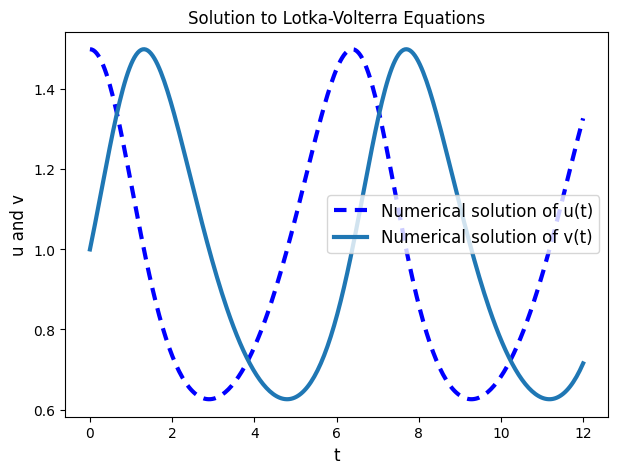

In [ ]:
plt.figure(figsize=(7,5))

plt.plot(t_list, y0_list, label="Numerical solution of u(t)", dashes=(3,2), color="blue",
        lw=3)
plt.plot(t_list, y1_list, label="Numerical solution of v(t)",
        lw=3)


plt.legend(loc="best", fontsize=12)
plt.title(r"Solution to Lotka-Volterra Equations")
plt.xlabel("t", fontsize=12)
plt.ylabel("u and v", fontsize=12)
plt.show()

In [ ]:
#Training dataset
t = np.linspace(0,12,1022)

x_analytical = y0_list
y_analytical = y1_list

In [ ]:
import tensorflow as tf

class PINN(tf.keras.Model):
    def __init__(self):
        super(PINN,self).__init__()
        self.dense1= tf.keras.layers.Dense(64, activation = 'tanh')
        self.dense2= tf.keras.layers.Dense(64, activation = 'sigmoid')
        self.dense3= tf.keras.layers.Dense(32, activation = 'sigmoid')
        self.dense4= tf.keras.layers.Dense(32, activation = 'tanh')
        self.dense5= tf.keras.layers.Dense(16, activation = 'sigmoid')
        self.dense6= tf.keras.layers.Dense(16, activation = 'tanh')
        self.dense7= tf.keras.layers.Dense(2, activation = None)

    def call(self,t):
        t=self.dense1(t)
        t=self.dense2(t)
        t=self.dense3(t)
        t=self.dense4(t)
        t=self.dense5(t)
        t=self.dense6(t)
        return self.dense7(t)

In [ ]:
def loss_fn(model,t):
    with tf.GradientTape() as tape1, tf.GradientTape() as tape2:
        tape1.watch(t)
        tape2.watch(t)
        output=model(t)
        x=output[:,0:1]
        y=output[:,1:2]
        dxdt = tape1.gradient(x,t)
        dydt = tape2.gradient(y,t)
        #Formula
        res_x = dxdt-x+x*y
        res_y = dydt-x*y+y
        #Initial Value
        init_loss_x = tf.square(x[0]-1.5)
        init_loss_y = tf.square(y[0]-1)
        loss = tf.reduce_mean(tf.square(res_x)) + tf.reduce_mean(tf.square(res_y)) + init_loss_x + init_loss_y
    return loss

In [ ]:
def train(model,t,epos,optimizer):
    for epo in range (epos):
        with tf.GradientTape() as tape:
            loss = loss_fn(model, t)
        grads = tape.gradient(loss, model.trainable_variables)
        optimizer.apply_gradients(zip(grads, model.trainable_variables))
        if epo%500 ==0:
            print(f'Epoch{epo}: Loss = {loss.numpy()}')

In [ ]:
model = PINN()
optimizer = tf.keras.optimizers.Adam(learning_rate=0.01)

In [ ]:
t = tf.convert_to_tensor(np.linspace(0,12,1022)[:,None],dtype=tf.float32)

In [ ]:
train(model,t,epos = 4000,optimizer = optimizer)

Epoch0: Loss = [3.7636173]
Epoch500: Loss = [0.00439891]
Epoch1000: Loss = [0.00190198]
Epoch1500: Loss = [0.00123807]
Epoch2000: Loss = [0.00057332]
Epoch2500: Loss = [0.00012403]
Epoch3000: Loss = [0.00117494]
Epoch3500: Loss = [9.795576e-05]


In [ ]:
t_test = np.linspace(0,12,300)[:,None]
x_pred,y_pred = model(t_test).numpy().T

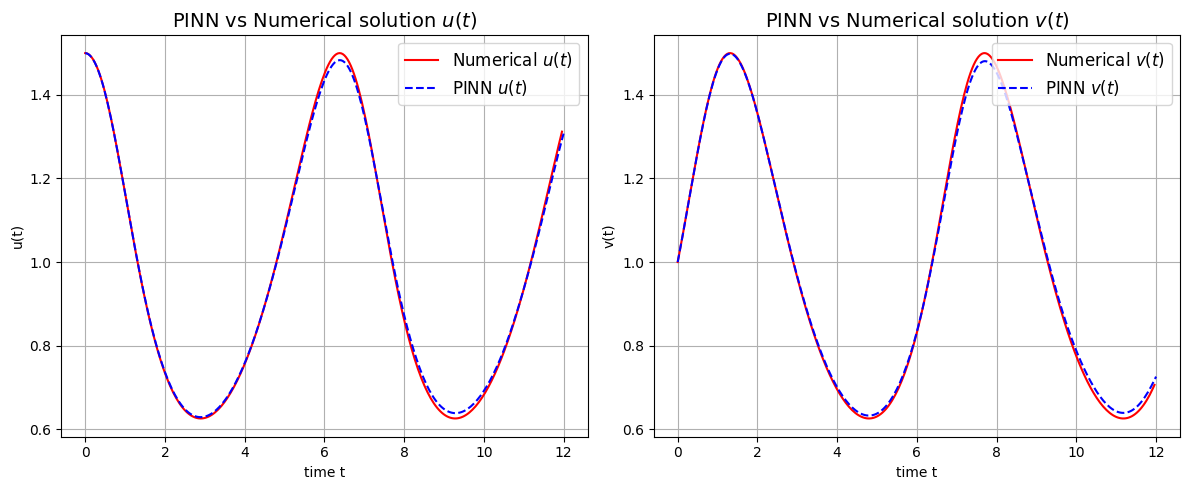

In [ ]:
plt.figure(figsize = (12,5))
plt.subplot(1,2,1)
#True Value
plt.plot(np.array(t_list[0:-1]),np.array((y0_list))[0:-1],label ="Numerical $u(t)$",color='red')
plt.plot(t_test,x_pred,'--',label ="PINN $u(t)$",color='blue')
plt.title(r'PINN vs Numerical solution $u(t)$',fontsize=14)
plt.xlabel(r'time t')
plt.ylabel(r'u(t)')
plt.grid(True)
plt.legend(fontsize=12,loc = "upper right")

plt.subplot(1,2,2)
#True Value
plt.plot(np.array(t_list[0:-1]),np.array((y1_list))[0:-1],label ="Numerical $v(t)$",color='red')
plt.plot(t_test,y_pred,'--',label ="PINN $v(t)$",color='blue')
plt.title(r'PINN vs Numerical solution $v(t)$',fontsize=14)
plt.xlabel(r'time t')
plt.ylabel(r'v(t)')
plt.grid(True)
plt.legend(fontsize=12,loc = "upper right")

plt.tight_layout()
plt.show()

In [ ]:
#L2 loss for PINN
np.sum((np.abs(np.array((y0_list))[0:]-x_pred)**2)+(np.abs(np.array((y1_list))[0:]-y_pred))**2)/300

0.00016066758012662276

In [ ]:
#Neurodiffeq

In [ ]:
import numpy as np
import matplotlib.pyplot as plt

In [ ]:
!pip install neurodiffeq
from neurodiffeq import diff

     ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 19.4/19.4 MB 16.3 MB/s eta 0:00:00
  Preparing metadata (setup.py) ... done
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 119.4/119.4 kB 8.4 MB/s eta 0:00:00
  Created wheel for neurodiffeq: filename=neurodiffeq-0.6.3-py3-none-any.whl size=132419 sha256=12f35e665db38eb8687ca8b3e75f2a167029639bc9e5752587e69f466a80b9ef
  Stored in directory: /root/.cache/pip/wheels/f6/e7/71/84c06f693bbf2ffd52a7c5ecd416c2a2ac053569b283171ddf
Successfully built neurodiffeq


In [ ]:
from neurodiffeq import diff      # the differentiation operation
from neurodiffeq.ode import solve # the ANN-based solver
from neurodiffeq.conditions import IVP   # the initial condition
from neurodiffeq.monitors import Monitor1D

In [ ]:
from neurodiffeq.ode import solve_system

In [ ]:
import torch

In [ ]:
from neurodiffeq.networks import FCNN # fully-connect neural network
import torch.nn as nn                 # PyTorch neural network module

In [ ]:
from neurodiffeq.generators import Generator1D

In [ ]:
from neurodiffeq.solvers import Solver1D

In [ ]:
import numpy as np
import matplotlib.pyplot as plt
import math

In [ ]:
from neurodiffeq.neurodiffeq import safe_diff as diff
from neurodiffeq.ode import solve, solve_system

In [ ]:
net_ho = FCNN(
    n_input_units=1,
    n_output_units=1,
    hidden_units=(64,),
    actv=nn.Tanh

)

net_ho_1 = FCNN(
    n_input_units=1,
    n_output_units=1,
    hidden_units=(64 ,),
    actv=nn.Sigmoid

)

net_ho_2 = FCNN(
    n_input_units=1,
    n_output_units=1,
    hidden_units=(32,),
    actv=nn.Tanh

)

net_ho_3 = FCNN(
    n_input_units=1,
    n_output_units=1,
    hidden_units=(32,),
    actv=nn.Sigmoid

)

net_ho_4 = FCNN(
    n_input_units=1,
    n_output_units=1,
    hidden_units=(16,),
    actv=nn.Sigmoid

)

net_ho_5 = FCNN(
    n_input_units=1,
    n_output_units=1,
    hidden_units=(16,),
    actv=nn.Tanh

)

net_ho_6 = FCNN(
    n_input_units=1,
    n_output_units=2,
)

/usr/local/lib/python3.10/dist-packages/neurodiffeq/ode.py:260: FutureWarning: The `solve_system` function is deprecated, use a `neurodiffeq.solvers.Solver1D` instance instead
  warnings.warn(
/usr/local/lib/python3.10/dist-packages/neurodiffeq/solvers.py:469: UserWarning: Passing `monitor` is deprecated, use a MonitorCallback and pass a list of callbacks instead
  warnings.warn("Passing `monitor` is deprecated, "


Training Progress:   0%|          | 0/4000 [00:00<?, ?it/s]

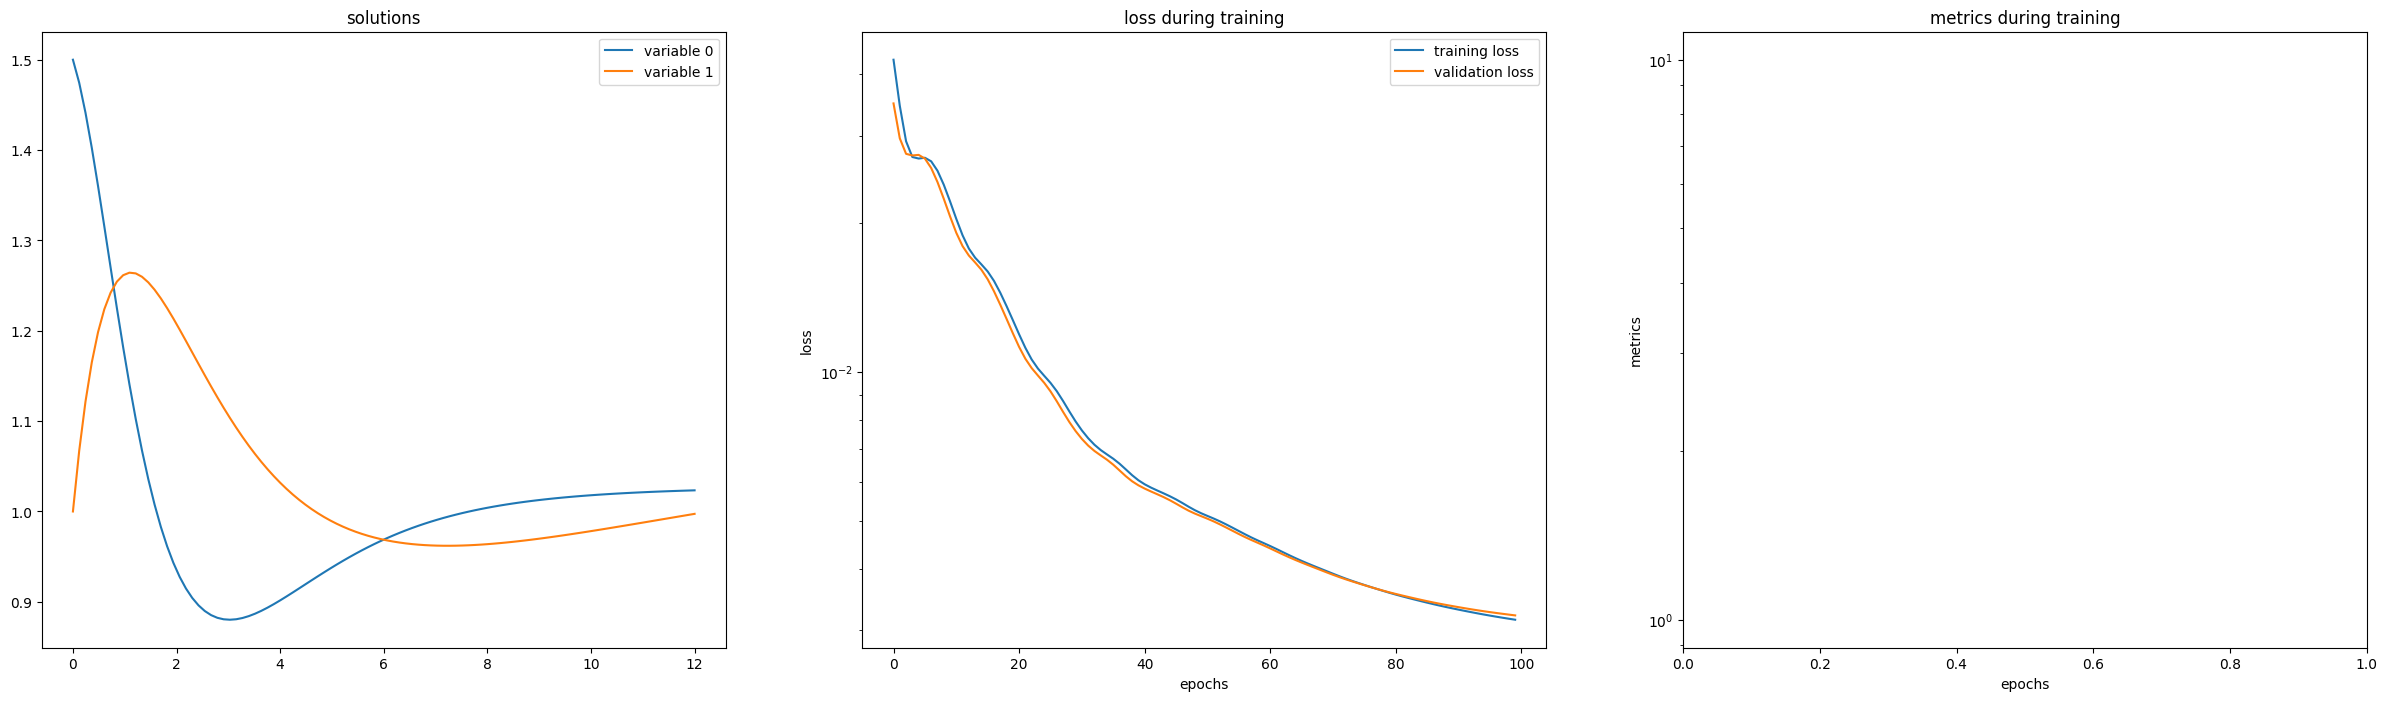

In [ ]:
# specify the ODE system
la=0.02
mu=0.0202

queueing_theory_equation = lambda y0, y1, t : [diff(y0, t)-y0+y0*y1,
                           diff(y1, t)-y0*y1+y1

                                                               ]
# specify the initial conditions
init_vals_pc = [
    IVP(t_0=0.0, u_0=1.5),
    IVP(t_0=0.0, u_0=1.0),
]
train_gen=Generator1D(size=1022,  t_min=0.0, t_max=12, method='equally-spaced')
# solve the ODE system
solution_pc, _, internal = solve_system(
    ode_system=queueing_theory_equation, conditions=init_vals_pc, t_min=0, t_max=12,
    train_generator=train_gen,
    max_epochs=4000,
    monitor=Monitor1D(t_min=0, t_max=12, check_every=100), return_internal=True,
    nets=[net_ho, net_ho_1, net_ho_2, net_ho_3, net_ho_4, net_ho_5, net_ho_6],
)

In [ ]:
internal

{'nets': [FCNN(
    (NN): Sequential(
      (0): Linear(in_features=1, out_features=64, bias=True)
      (1): Tanh()
      (2): Linear(in_features=64, out_features=1, bias=True)
    )
  ),
  FCNN(
    (NN): Sequential(
      (0): Linear(in_features=1, out_features=64, bias=True)
      (1): Sigmoid()
      (2): Linear(in_features=64, out_features=1, bias=True)
    )
  ),
  FCNN(
    (NN): Sequential(
      (0): Linear(in_features=1, out_features=32, bias=True)
      (1): Tanh()
      (2): Linear(in_features=32, out_features=1, bias=True)
    )
  ),
  FCNN(
    (NN): Sequential(
      (0): Linear(in_features=1, out_features=32, bias=True)
      (1): Sigmoid()
      (2): Linear(in_features=32, out_features=1, bias=True)
    )
  ),
  FCNN(
    (NN): Sequential(
      (0): Linear(in_features=1, out_features=16, bias=True)
      (1): Sigmoid()
      (2): Linear(in_features=16, out_features=1, bias=True)
    )
  ),
  FCNN(
    (NN): Sequential(
      (0): Linear(in_features=1, out_features=16

In [ ]:
from time import time
time0=time()
ts = np.linspace(0, 12, 300)
u_net = solution_pc(ts, to_numpy=True)
time1=time()

In [ ]:
time=time1-time0
time

0.0059735774993896484

In [ ]:
#L2 loss
np.sum(np.abs(np.array((y0_list))[0:]-u_net[0])**2+np.abs(np.array((y1_list))[0:]-u_net[1])**2)/300

0.09856924962934631

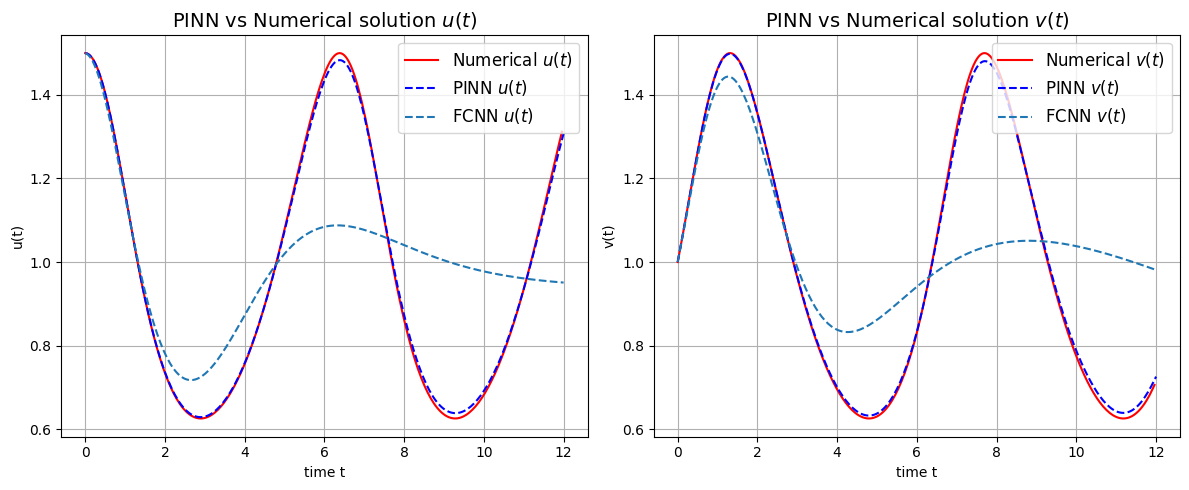

In [ ]:
plt.figure(figsize = (12,5))
plt.subplot(1,2,1)
#True Value
plt.plot(np.array(t_list[0:-1]),np.array((y0_list))[0:-1],label ="Numerical $u(t)$",color='red')
plt.plot(t_test,x_pred,'--',label ="PINN $u(t)$",color='blue')
plt.plot(t_test,u_net[0],'--',label ="FCNN $u(t)$")
plt.title(r'PINN vs Numerical solution $u(t)$',fontsize=14)
plt.xlabel(r'time t')
plt.ylabel(r'u(t)')
plt.grid(True)
plt.legend(fontsize=12,loc = "upper right")

plt.subplot(1,2,2)
#True Value
plt.plot(np.array(t_list[0:-1]),np.array((y1_list))[0:-1],label ="Numerical $v(t)$",color='red')
plt.plot(t_test,y_pred,'--',label ="PINN $v(t)$",color='blue')
plt.plot(t_test,u_net[1],'--',label ="FCNN $v(t)$")
plt.title(r'PINN vs Numerical solution $v(t)$',fontsize=14)
plt.xlabel(r'time t')
plt.ylabel(r'v(t)')
plt.grid(True)
plt.legend(fontsize=12,loc = "upper right")

plt.tight_layout()
plt.show()

In [ ]:
!pip install deepxde

   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 184.4/184.4 kB 3.6 MB/s eta 0:00:00
   ━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━ 107.8/107.8 kB 8.5 MB/s eta 0:00:00


In [ ]:
import deepxde as dde
import matplotlib.pyplot as plt

Using backend: tensorflow.compat.v1
Other supported backends: tensorflow, pytorch, jax, paddle.
paddle supports more examples now and is recommended.
Instructions for updating:
non-resource variables are not supported in the long term


No backend selected.
Finding available backend...
Found tensorflow.compat.v1
Setting the default backend to "tensorflow.compat.v1". You can change it in the ~/.deepxde/config.json file or export the DDE_BACKEND environment variable. Valid options are: tensorflow.compat.v1, tensorflow, pytorch, jax, paddle (all lowercase)


In [ ]:
import numpy as np

In [ ]:
# Define the time domain:
T = 12
num_samples = 1022
num_boundary = 8

# Defining parameters:
alpha = 1
beta = 1
delta = 1
gamma = 1

# Set initial values:
x0 = 1.5
y0 = 1

In [ ]:
# Define the ODE-system:
def ode_system(input, output):

    # Get the outputs:
    x = output[:, 0:1]
    y = output[:, 1:2]

    # Get the derivatives:
    dx_t = dde.grad.jacobian(output, input, i=0)
    dy_t = dde.grad.jacobian(output, input, i=1)

    # Return the equations:
    return [
        dx_t - alpha * x + beta * x * y,
        dy_t - gamma * x * y + delta * y,
    ]
# Define the time domain of the ODE:
geom = dde.geometry.TimeDomain(0.0, T)

# Function for determening if x on boundary or not:
def boundary(_, on_initial):
    return on_initial

# Set the intial values:
ic1 = dde.IC(geom, lambda X: x0, boundary, component=0)
ic2 = dde.IC(geom, lambda X: y0, boundary, component=1)
# Create the equation:
data = dde.data.PDE(geom, ode_system, [ic1, ic2], num_samples, num_boundary, num_test=300)
# Define and create the neural network:
layer_size = [1] +[64]*2+[32] * 2 + [16]*2+ [2]
activation = "tanh"
initializer = "Glorot normal"
net = dde.maps.FNN(layer_size, activation, initializer)
# Combine the data and network into a model:
model = dde.Model(data, net)
# Training:
model.compile("adam", lr=0.01, loss_weights= [10, 5, 5, 1])
losshistory, train_state = model.train(epochs=4000, display_every= 1000)

#model.compile("L-BFGS")
#losshistory, train_state = model.train()

Compiling model...
Building feed-forward neural network...
'build' took 0.193172 s

'compile' took 1.821134 s

Training model...

Step      Train loss                                  Test loss                                   Test metric
0         [5.29e-02, 9.80e-01, 1.12e+01, 1.00e+00]    [5.28e-02, 9.82e-01, 1.12e+01, 1.00e+00]    []  
1000      [8.74e-03, 9.99e-03, 1.10e-04, 3.52e-05]    [8.73e-03, 1.01e-02, 1.10e-04, 3.52e-05]    []  
2000      [4.42e-03, 7.57e-03, 9.29e-05, 9.19e-08]    [4.42e-03, 7.63e-03, 9.29e-05, 9.19e-08]    []  
3000      [6.54e-03, 7.08e-03, 5.19e-04, 1.99e-04]    [6.59e-03, 7.14e-03, 5.19e-04, 1.99e-04]    []  
4000      [9.99e-05, 1.83e-04, 1.16e-06, 7.82e-08]    [9.77e-05, 1.73e-04, 1.16e-06, 7.82e-08]    []  

Best model at step 4000:
  train loss: 2.84e-04
  test loss: 2.71e-04
  test metric: []

'train' took 44.395468 s



Compiling model...
'compile' took 0.575573 s

Training model...

Step      Train loss                                  Test loss                                   Test metric
4000      [9.99e-06, 3.66e-05, 2.33e-07, 7.82e-08]    [9.77e-06, 3.45e-05, 2.33e-07, 7.82e-08]    []  
4016      [9.99e-06, 3.66e-05, 2.33e-07, 7.82e-08]    [9.77e-06, 3.45e-05, 2.33e-07, 7.82e-08]    []  

Best model at step 4000:
  train loss: 4.69e-05
  test loss: 4.46e-05
  test metric: []

'train' took 1.903986 s



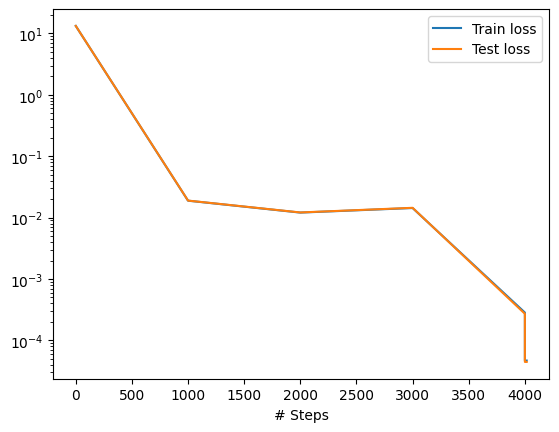

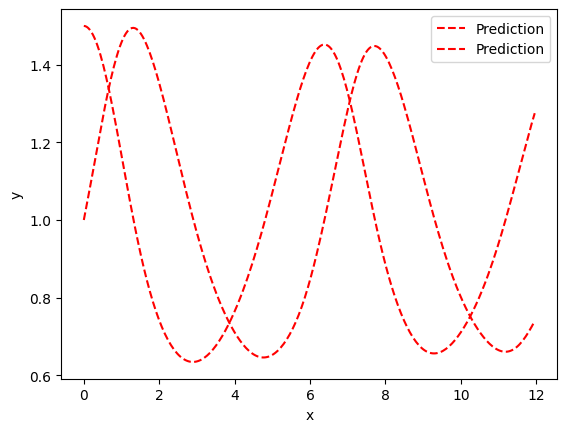

In [ ]:
model.compile("L-BFGS")
losshistory, train_state = model.train()
# Plot and save:
dde.saveplot(losshistory, train_state, issave=False, isplot=True)

In [ ]:
x=model.predict(np.expand_dims(np.linspace(0,12,300),axis=-1))[:,0]
y=model.predict(np.expand_dims(np.linspace(0,12,300),axis=-1))[:,1]

In [ ]:
t=np.linspace(0,12,1022)

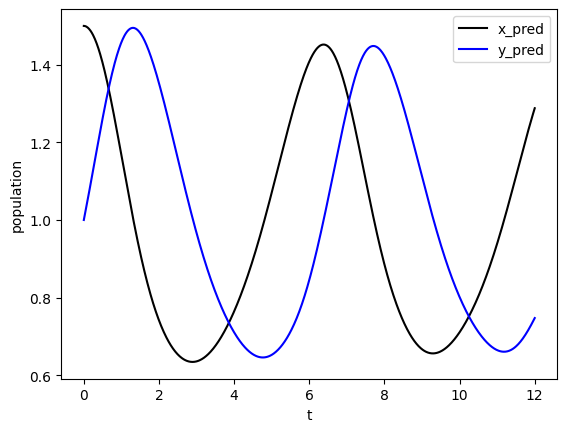

In [ ]:
# Plot the two solutions in the same plot:
t = t.reshape(num_samples, 1)
sol_pred = model.predict(t)
x_pred_DDE = sol_pred[:, 0:1]
y_pred_DDE = sol_pred[:, 1:2]

plt.xlabel("t")
plt.ylabel("population")
plt.plot(t, x_pred_DDE, color="black", label="x_pred")
plt.plot(t, y_pred_DDE, color="blue", label="y_pred")
#plt.plot(t, x_true, color="black", label="x_true", linestyle="dashed")
#plt.plot(t, y_true, color="blue", label="y_true", linestyle="dashed")
plt.legend()
plt.show()

#print("L2 relative error for x:", dde.metrics.l2_relative_error(x_true, x_pred))
#print("L2 relative error for y:", dde.metrics.l2_relative_error(y_true, y_pred))

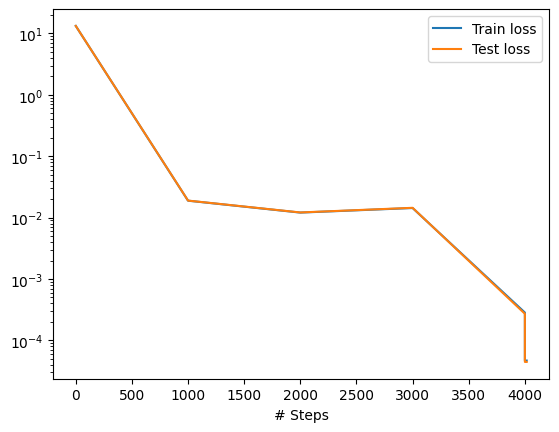

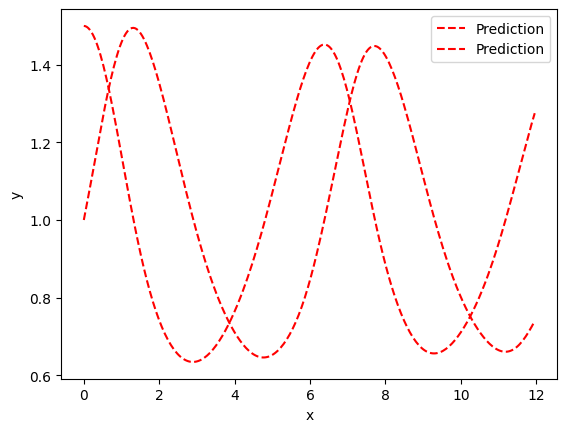

In [ ]:
dde.saveplot(losshistory, train_state, issave=False, isplot=True)

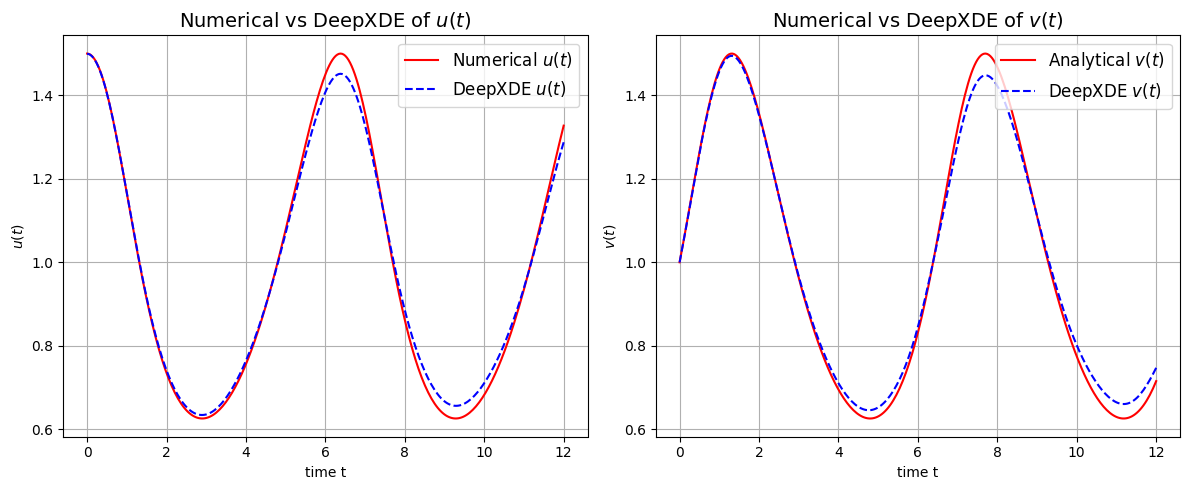

In [ ]:
plt.figure(figsize = (12,5))
plt.subplot(1,2,1)
#True Value
plt.plot(np.array(t_list),np.array(y0_list),label ="Numerical $u(t)$",color='red')
plt.plot(np.linspace(0,12,300),x,'--',label ="DeepXDE $u(t)$",color='blue')
plt.title(r'Numerical vs DeepXDE of $u(t)$',fontsize=14)
plt.xlabel(r'time t')
plt.ylabel(r'$u(t)$')
plt.grid(True)
plt.legend(fontsize=12,loc = "upper right")

plt.subplot(1,2,2)
#True Value
plt.plot(np.array(t_list),np.array(y1_list),label ="Analytical $v(t)$",color='red')
plt.plot(np.linspace(0,12,300),y,'--',label ="DeepXDE $v(t)$",color='blue')
plt.title(r'Numerical vs DeepXDE of $v(t)$',fontsize=14)
plt.xlabel(r'time t')
plt.ylabel(r'$v(t)$')
plt.grid(True)
plt.legend(fontsize=12,loc = "upper right")

plt.tight_layout()
plt.show()

In [ ]:
#L2 loss
np.sum(np.abs(np.array((y0_list))[0:]-x)**2+np.abs(np.array((y1_list))[0:]-y)**2)/300

0.0010492104080519302

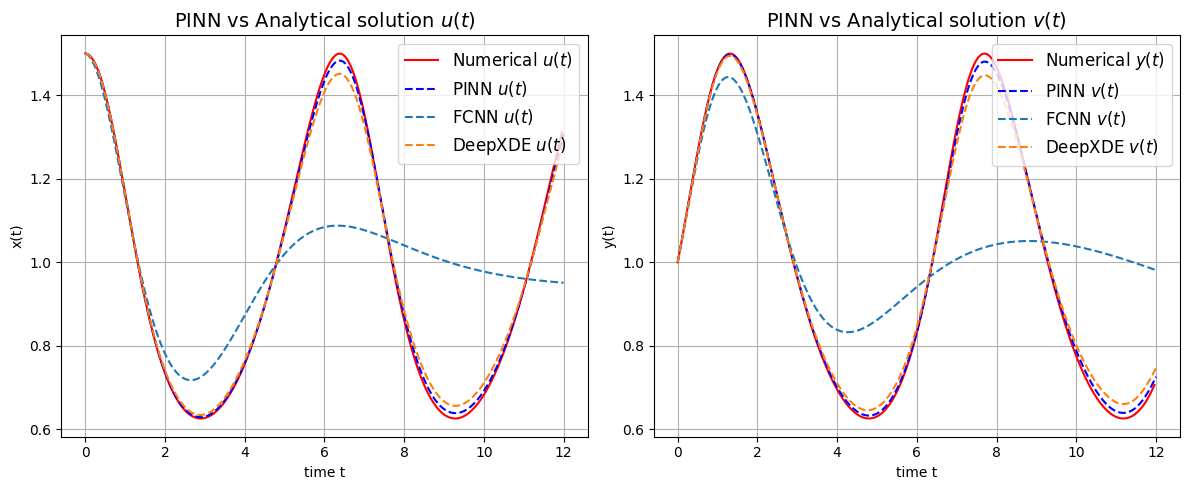

In [ ]:
plt.figure(figsize = (12,5))
plt.subplot(1,2,1)
#True Value
plt.plot(np.array(t_list[0:-1]),np.array((y0_list))[0:-1],label ="Numerical $u(t)$",color='red')
plt.plot(t_test,x_pred,'--',label ="PINN $u(t)$",color='blue')
plt.plot(t_test,u_net[0],'--',label ="FCNN $u(t)$")
plt.plot(t_test,x,'--',label ="DeepXDE $u(t)$")
plt.title(r'PINN vs Analytical solution $u(t)$',fontsize=14)
plt.xlabel(r'time t')
plt.ylabel(r'x(t)')
plt.grid(True)
plt.legend(fontsize=12,loc = "upper right")

plt.subplot(1,2,2)
#True Value
plt.plot(np.array(t_list[0:-1]),np.array((y1_list))[0:-1],label ="Numerical $y(t)$",color='red')
plt.plot(t_test,y_pred,'--',label ="PINN $v(t)$",color='blue')
plt.plot(t_test,u_net[1],'--',label ="FCNN $v(t)$")
plt.plot(t_test,y,'--',label ="DeepXDE $v(t)$")
plt.title(r'PINN vs Analytical solution $v(t)$',fontsize=14)
plt.xlabel(r'time t')
plt.ylabel(r'y(t)')
plt.grid(True)
plt.legend(fontsize=12,loc = "upper right")

plt.tight_layout()
plt.show()